In [ ]:
import sys
sys.path.append("../source")

import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import matplotlib.pyplot as plt
import diffrax as dfx

from core.spacing import LinearSpacing, SpacingExtent, NUM_GHOSTS
from core.grid import Grid
from core.statevector import StateVector
from core.rhsevolution import get_rhs
from matter.scalarmatter import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.bssnstatevariables import idx_phi, idx_lapse
from bssn.constraintsdiagnostic import get_constraints_diagnostic

In [ ]:
A = 0.22 # amplitude
r0 = 0
sigma = 1.0

num_points = 401
r_max = 10.0

T = 6.0 # maximum time evolution
num_output_times = 101 # number of times to save the output
dt0 = 0.005 

matter = ScalarMatter(a_scalar_mu=0.0)
state_vector = StateVector(matter)

spacing = LinearSpacing(
    num_points=num_points,
    r_max=r_max,
    extent=SpacingExtent.HALF,
)
grid = Grid(spacing, state_vector)
background = FlatSphericalBackground(grid.r)

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)
r_physical = grid.r[physical]
dr = grid.derivs.dx

In [22]:
def scalar_profile(r, amplitude, sigma):
    return amplitude * r**2 * jnp.exp(-(r / sigma)**2)

scalar_profile_dr = jax.grad(scalar_profile, argnums=0)




In [23]:
def solve_psi(r_aux, dr, amplitude, r0, sigma):
    du_dr = jax.vmap(
    scalar_profile_dr,
    in_axes=(0, None, None),)(r_aux, amplitude, sigma)

    source = jnp.pi * du_dr**2
    n = r_aux.size

    main_diag = source * dr**2 - 2.0
    main_diag = main_diag.at[0].add(1.0 - dr / r_aux[0])

    outer_factor = (
        2.0 * dr / r_aux[-1]
        * (1.0 + dr / r_aux[-1])
    )
    main_diag = main_diag.at[-1].add(-outer_factor)

    lower_diag = jnp.zeros_like(r_aux)
    upper_diag = jnp.zeros_like(r_aux)

    upper_diag = upper_diag.at[:-1].set(
        1.0 + dr / r_aux[:-1]
    )
    lower_diag = lower_diag.at[1:].set(
        1.0 - dr / r_aux[1:]
    )
    lower_diag = lower_diag.at[-1].set(2.0)

    rhs = jnp.zeros_like(r_aux)
    rhs = rhs.at[-1].set(-outer_factor)

    psi = jax.lax.linalg.tridiagonal_solve(
        lower_diag,
        main_diag,
        upper_diag,
        rhs[:, None],
    )[:, 0]

    return psi

In [24]:
def make_initial_state(amplitude):
    psi_physical = solve_psi(
        r_physical, dr, amplitude, r0, sigma
    )
    u_physical = scalar_profile(
        r_physical, amplitude, sigma
    )

    state = jnp.zeros((grid.NUM_VARS, grid.N))

    state = state.at[idx_phi, physical].set(jnp.log(psi_physical))
    state = state.at[idx_lapse, physical].set(psi_physical**-2)
    state = state.at[matter.idx_u, physical].set(u_physical)
    state = state.at[matter.idx_v, physical].set(0.0)

    state = grid.fill_boundaries(state)
    return state.reshape(-1)

In [ ]:
def evolve(amplitude):
    y0 = make_initial_state(amplitude) # builds state at t0

    def rhs_for_diffrax(t, state, args):
        return get_rhs(t, state, grid, background, matter) # this is just a wrapper function because diffrax expects different inputs

    def collapse_condition(t, state, args, **kwargs):
        state_grid = state.reshape(grid.NUM_VARS, grid.N) # reshape it back into a grid to get lapse value
        central_lapse = state_grid[idx_lapse, NUM_GHOSTS] # pick column 3 to ignore the first 3 ghost points
        return central_lapse <= 5e-3 # collapse trigger, triggers supercritical when lapse is less than 0.005

    def save_central_scalar(t, state, args):
        state_grid = state.reshape(grid.NUM_VARS, grid.N) # this function returns u at the first physical radius at the current time
        return state_grid[matter.idx_u, NUM_GHOSTS]
        
    save_times = jnp.linspace(0.0, T, num_output_times, endpoint=False)
    saveat = dfx.SaveAt(
        subs=[
            # Save full states at num output times for plots incl final time
            dfx.SubSaveAt(ts=save_times, t1=True), # this si the first save stream, accessed by solution.ts[0] 

            # Save only the central scalar at every solver step, this is used to calculate L
            dfx.SubSaveAt(
                t0=True,
                steps=True,
                fn=save_central_scalar,
            ),
        ]
    )

    solution = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs_for_diffrax),
        solver=dfx.Dopri5(), #Runge Kutta
        t0=0.0, # start time
        t1=T, # end time
        dt0=dt0, #step size
        y0=y0, # initial state
        stepsize_controller=dfx.ConstantStepSize(), # fixed steps for now
        saveat=saveat,
        adjoint=dfx.ForwardMode(), # got an error and needed to add this - look into it
        event=dfx.Event(collapse_condition), # stop when collapse condition is true
        max_steps=1500,
    )

    return solution # this is all the evolved engrenage variables and histories

# Calculate L and final lapse

def run_metrics(amplitude):
    solution = evolve(amplitude)

    # First grid point, saved at solver steps  #UPDATE CENTRAL -> FIRST GRID POINT
    central_times = solution.ts[1]
    central_u = solution.ys[1]

    # This is needed because the solver uses fewer steps if stops early eg so it pads with inf values 
    valid = jnp.isfinite(central_times) & jnp.isfinite(central_u)
    u_clean = jnp.where(valid, central_u, 0.0) # replaces inf values with 0

    changes = jnp.abs(jnp.diff(u_clean)) # subtracts consecutive entries
    valid_pairs = valid[:-1] & valid[1:] # mark a pair as vaild only when both are valid
    L = jnp.sum(jnp.where(valid_pairs, changes, 0.0))


    state_times = solution.ts[0]
    state_history = solution.ys[0]
    valid_state_times = jnp.isfinite(state_times)
    last_index = jnp.sum(valid_state_times.astype(jnp.int32)) - 1 # subtract one to get the last valid index

    final_state = state_history[last_index].reshape(grid.NUM_VARS, grid.N)
    final_lapse = final_state[idx_lapse, NUM_GHOSTS] # select the lapse at the final time at the first physical radius

    
    event_fired = solution.result == dfx.RESULTS.event_occurred

    return jnp.stack([L, final_lapse]), event_fired


def evaluate_amplitude(A):
    amplitude = jnp.asarray(A, dtype=jnp.float64)

    # JVP differentiates L and final_lapse; event_fired is auxiliary info.
    values, derivatives, event_fired = jax.jvp(
        run_metrics,
        (amplitude,),
        (jnp.ones_like(amplitude),),
        has_aux=True,
    )

    L = float(values[0])
    final_lapse = float(values[1])
    dL_dA = float(derivatives[0])

    if bool(event_fired):
        outcome = "super"
    elif not all(isfinite(x) for x in (L, dL_dA, final_lapse)):
        outcome = "failed"
    elif final_lapse > 0.60:
        outcome = "sub"
    else:
        outcome = "ambiguous"

    return {
        "A": float(A),
        "L": L,
        "dL_dA": dL_dA,
        "final_lapse": final_lapse,
        "outcome": outcome,
    }

In [ ]:

solution = evolve(jnp.asarray(A, dtype=jnp.float64))

In [ ]:
from itertools import combinations
from math import isfinite
from statistics import median


def estimate_b(runs):
    # Use only subcritical runs with positive, finite gradients.
    usable = [
        run for run in runs
        if run["outcome"] == "sub"  # ONLY include if the run was subcritical, a gradient was recorded and the gradient is finite and positive
        and run.get("dL_dA") is not None
        and isfinite(run["dL_dA"])
        and run["dL_dA"] > 0
    ]

    b_values = []

    # Estimate b from pairs using:
    # b = (A2 - A1) / (1/(dL/dA2) - 1/(dL/dA1))
    for run1, run2 in combinations(usable, 2):
        A1, g1 = run1["A"], run1["dL_dA"]
        A2, g2 = run2["A"], run2["dL_dA"]

        denominator = 1.0 / g2 - 1.0 / g1
        if denominator != 0:
            b = (A2 - A1) / denominator
            if isfinite(b) and b < 0:
                b_values.append(b)

    return median(b_values) if b_values else None


def propose_next_amplitude(runs):
    sub = [run["A"] for run in runs if run["outcome"] == "sub"] # grouping outcomes into sub and supercritical lists
    supercritical = [run["A"] for run in runs if run["outcome"] == "super"]

    if not sub or not supercritical:
        raise ValueError("Need at least one subcritical and one supercritical run.")

    lower = max(sub)
    upper = min(supercritical)

    if lower >= upper:
        raise ValueError("The recorded runs do not form a valid bracket.")

    b = estimate_b(runs) # use previous subcritical runs to evaluate b, if not enough previous runs it returns none

    if b is not None:
        usable_sub = [ # same criteria as before
            run for run in runs
            if run["outcome"] == "sub"
            and run.get("dL_dA") is not None
            and isfinite(run["dL_dA"])
            and run["dL_dA"] > 0
        ]

        # Use the subcritical run with the largest gradient 
        anchor = max(usable_sub, key=lambda run: abs(run["dL_dA"]))
        candidate = anchor["A"] - b / anchor["dL_dA"] # compute A*

        # Keep the proposal inside the known sub/super bracket.
        if lower < candidate < upper:
            return candidate, f"gradient proposal inside bracket; b={b:.4g}"

    # if b cant be estimated or if the candidate is outside the bracket, return the midpoint of the bracket
    return 0.5 * (lower + upper), "not enough reliable gradient information; bracket midpoint"

def run_next_amplitude(runs, first_A=0.22):
    if not runs:
        A_next = first_A # if there is no previous runs
        reason = "first run"

    elif runs[-1]["outcome"] in ("ambiguous", "failed"):
        raise ValueError(
            "The latest run is ambiguous or failed. Resolve it before continuing." # Note: Still need to extend runs for ambiguous cases
        )

    else:
        sub = [run for run in runs if run["outcome"] == "sub"]
        supercritical = [run for run in runs if run["outcome"] == "super"]

        if not sub or not supercritical: # if we dont have a bracket yet
            # Startup: move toward the other side of the threshold.
            last = runs[-1]

            if last["outcome"] == "sub":
                A_next = 1.15 * last["A"]
                reason = "startup: increase after subcritical run"
            else:
                A_next = 0.87 * last["A"]
                reason = "startup: decrease after supercritical run"

        else:
            # Once both sides are known, use the bracketed gradient proposal.
            A_next, reason = propose_next_amplitude(runs)

    record = evaluate_amplitude(A_next)
    runs.append(record)

    print(f"A = {record['A']:.8f}")
    print(f"Outcome: {record['outcome']}")
    print(f"L = {record['L']:.6g}")
    print(f"dL/dA = {record['dL_dA']:.6g}")
    print(f"Final central lapse = {record['final_lapse']:.6g}")
    print("Proposal rule:", reason)

    return record


In [37]:
runs = []
run_next_amplitude(runs)

A = 0.22000000
Outcome: sub
L = 0.519088
dL/dA = 2.9842
Final central lapse = 0.960369
Proposal rule: first run


{'A': 0.22,
 'L': 0.519087552047046,
 'dL_dA': 2.9842042068503862,
 'final_lapse': 0.9603688354982822,
 'outcome': 'sub'}

In [39]:
import matplotlib.pyplot as plt
import numpy as np

b = estimate_b(runs)

sub_runs = [
    run for run in runs
    if run["outcome"] == "sub"
    and run.get("dL_dA") is not None
    and isfinite(run["dL_dA"])
    and run["dL_dA"] > 0
]
super_runs = [run for run in runs if run["outcome"] == "super"]

anchor = max(sub_runs, key=lambda run: run["dL_dA"])
A_star_est = anchor["A"] - b / anchor["dL_dA"]

lower = max(run["A"] for run in sub_runs)
upper = min(run["A"] for run in super_runs)

print("Estimated A*:", A_star_est)
print("Current bracket:", lower, "to", upper)

Estimated A*: 0.38166123848524747
Current bracket: 0.3596869374999999 to 0.3847813749999999


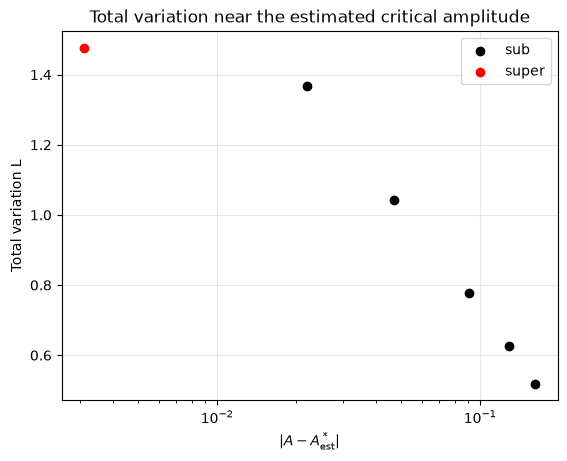

In [40]:
for outcome, colour in [("sub", "black"), ("super", "red")]:
    selected = [run for run in runs if run["outcome"] == outcome]
    distances = [abs(run["A"] - A_star_est) for run in selected]

    plt.scatter(
        distances,
        [run["L"] for run in selected],
        color=colour,
        label=outcome,
    )

plt.xscale("log")
plt.xlabel(r"$|A-A^*_{\mathrm{est}}|$")
plt.ylabel("Total variation L")
plt.title("Total variation near the estimated critical amplitude")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [38]:
for _ in range(5):
    record = run_next_amplitude(runs)

    if record["outcome"] == "ambiguous":
        print("Stopping: this run needs a longer evolution before continuing.")
        break

A = 0.25300000
Outcome: sub
L = 0.625893
dL/dA = 3.52349
Final central lapse = 0.944045
Proposal rule: startup: increase after subcritical run
A = 0.29095000
Outcome: sub
L = 0.7777
dL/dA = 4.60038
Final central lapse = 0.916984
Proposal rule: startup: increase after subcritical run
A = 0.33459250
Outcome: sub
L = 1.04356
dL/dA = 8.62337
Final central lapse = 0.859696
Proposal rule: startup: increase after subcritical run
A = 0.38478137
Outcome: super
L = 1.47714
dL/dA = 10.845
Final central lapse = 0.00491683
Proposal rule: startup: increase after subcritical run
A = 0.35968694
Outcome: sub
L = 1.36701
dL/dA = 22.0321
Final central lapse = 0.773903
Proposal rule: not enough reliable gradient information; bracket midpoint


In [29]:
run_next_amplitude(runs)

A = 0.38296420
Outcome: super
L = 1.59719
dL/dA = 68.0651
Final central lapse = 0.00494077
Proposal rule: gradient proposal inside bracket; b=-0.4866


{'A': 0.38296420316215335,
 'L': 1.5971851021624341,
 'dL_dA': 68.06509156224608,
 'final_lapse': 0.004940767391543943,
 'outcome': 'super'}

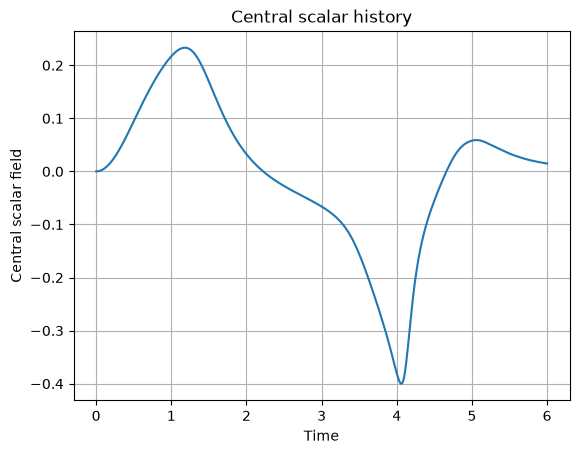

In [31]:
import numpy as np
import matplotlib.pyplot as plt

central_times = solution.ts[1]
central_u = solution.ys[1]

# Ignore the inf padding Diffrax may add after an event.
valid = jnp.isfinite(central_times) & jnp.isfinite(central_u)
times_plot = np.asarray(central_times[valid])
u_plot = np.asarray(central_u[valid])

plt.plot(times_plot, u_plot)
plt.xlabel("Time")
plt.ylabel("Central scalar field")
plt.title("Central scalar history")
plt.grid()
plt.show()

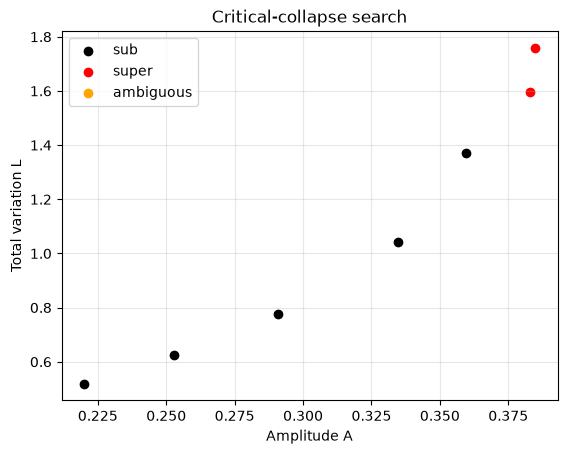

In [32]:
for outcome, colour in [
    ("sub", "black"),
    ("super", "red"),
    ("ambiguous", "orange"),
]:
    selected = [run for run in runs if run["outcome"] == outcome]
    plt.scatter(
        [run["A"] for run in selected],
        [run["L"] for run in selected],
        color=colour,
        label=outcome,
    )

plt.xlabel("Amplitude A")
plt.ylabel("Total variation L")
plt.title("Critical-collapse search")
plt.legend()
plt.grid(alpha=0.3)
plt.show()